# 🎯 End-to-End Machine Learning Pipeline

This notebook follows the standard Machine Learning workflow:

```
Dataset
   ↓
EDA / Preprocessing
   ↓
Train-Test Split
   ↓
Scaling / Encoding (if required)
   ↓
Model
   ↓
Hyperparameter Tuning
   ↓
5-Fold Cross Validation
   ↓
Evaluation
   ↓
Final Output
```


### 0. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
print("✓ Common data science and visualization libraries imported.")

✓ Common data science and visualization libraries imported.


---
## Step 1: Dataset
Load the Wisconsin Breast Cancer classification dataset.


In [40]:
from sklearn.datasets import load_breast_cancer

# Load dataset as pandas DataFrame
cancer_data = load_breast_cancer(as_frame=True)
df = cancer_data.frame

print(f"Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Target Column: 'target' -> {list(cancer_data.target_names)}")
print("Class Mapping: 0 = Malignant (cancerous), 1 = Benign (non-cancerous)")

# First 5 rows
df.head()

Dataset Dimensions: 569 rows × 31 columns
Target Column: 'target' -> [np.str_('malignant'), np.str_('benign')]
Class Mapping: 0 = Malignant (cancerous), 1 = Benign (non-cancerous)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


---
## Step 2: EDA / Preprocessing
Inspect data types, detect missing values, examine descriptive statistics, and check target class balance.


=== 2.1 Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64

C:\Users\priya\AppData\Local\Temp\ipykernel_21044\1380608845.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2', ax=axes[0])
C:\Users\priya\AppData\Local\Temp\ipykernel_21044\1380608845.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Malignant (0)', 'Benign (1)'])
C:\Users\priya\AppData\Local\Temp\ipykernel_21044\1380608845.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='mean radius', data=df, palette='Set2', ax=axes[1])
C:\Users\priya\AppData\Local\Temp\ipykernel_21044\1380608845.py:27: UserWarning: set_ticklabels() 

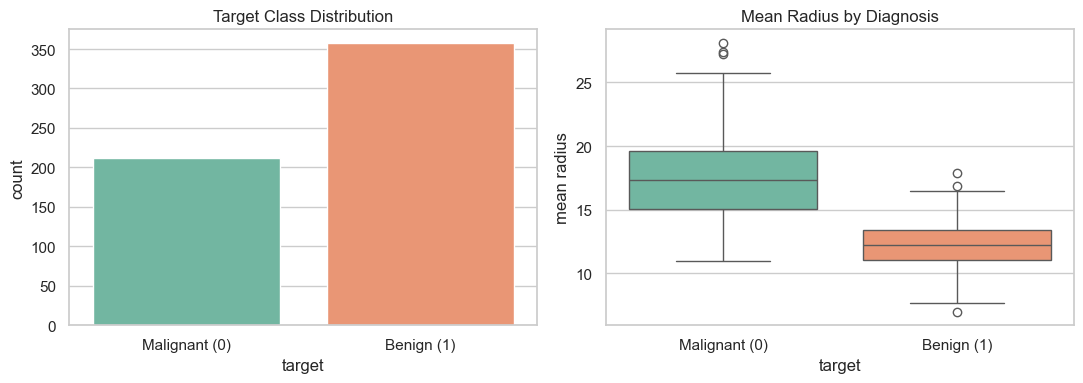

In [3]:
print("=== 2.1 Dataset Information ===")
df.info()

print("\n=== 2.2 Missing Value Audit ===")
null_counts = df.isnull().sum().sum()
print(f"Total Missing Values in Dataset: {null_counts}")

print("\n=== 2.3 Statistical Summary (First 5 Features) ===")
print(df.iloc[:, :5].describe().round(3))

# Target Class Distribution Check
target_counts = df['target'].value_counts()
print("\n=== 2.4 Target Class Balance ===")
print(target_counts)

# Quick EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Target countplot
sns.countplot(x='target', data=df, palette='Set2', ax=axes[0])
axes[0].set_title("Target Class Distribution")
axes[0].set_xticklabels(['Malignant (0)', 'Benign (1)'])

# 2. Feature boxplot (mean radius vs diagnosis)
sns.boxplot(x='target', y='mean radius', data=df, palette='Set2', ax=axes[1])
axes[1].set_title("Mean Radius by Diagnosis")
axes[1].set_xticklabels(['Malignant (0)', 'Benign (1)'])

plt.tight_layout()
plt.show()

---
## Step 3: Train-Test Split
Separate independent features ($X$) and target ($y$). Perform an 80/20 stratified split to preserve class proportions.


In [4]:
from sklearn.model_selection import train_test_split

# Separate Features (X) and Target (y)
X = df.drop(columns=['target'])
y = df['target']

# 80% Train, 20% Test (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training Features (X_train): {X_train.shape}, Labels (y_train): {y_train.shape}")
print(f"Testing Features  (X_test):  {X_test.shape},  Labels (y_test):  {y_test.shape}")
print("\nTrain Class Distribution:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest Class Distribution:\n", y_test.value_counts(normalize=True).round(3))

Training Features (X_train): (455, 30), Labels (y_train): (455,)
Testing Features  (X_test):  (114, 30),  Labels (y_test):  (114,)

Train Class Distribution:
 target
1    0.626
0    0.374
Name: proportion, dtype: float64

Test Class Distribution:
 target
1    0.632
0    0.368
Name: proportion, dtype: float64


---
## Step 4: Scaling / Encoding (if required)
- **Feature Scaling**: Standardize features using `StandardScaler` (fit strictly on training data, then transform both train and test to prevent data leakage).
- **Encoding**: *All 30 features are numerical; if categorical columns existed, `OneHotEncoder` or `pd.get_dummies` would be applied here.*


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit strictly on train data, transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✓ Feature scaling complete.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"Feature 0 Mean after scaling: {X_train_scaled[:, 0].mean():.4f} (≈ 0)")
print(f"Feature 0 Std after scaling:  {X_train_scaled[:, 0].std():.4f} (≈ 1)")

✓ Feature scaling complete.
X_train_scaled shape: (455, 30)
Feature 0 Mean after scaling: -0.0000 (≈ 0)
Feature 0 Std after scaling:  1.0000 (≈ 1)


---
## Step 5: Model
Initialize candidate Machine Learning model:
- **Model Choice**: `RandomForestClassifier` (High-performing ensemble tree-based algorithm).


In [6]:
from sklearn.ensemble import RandomForestClassifier

# Initialize baseline Random Forest model
base_model = RandomForestClassifier(random_state=42)

# Train on scaled training data
base_model.fit(X_train_scaled, y_train)

# Baseline training & testing accuracy
base_train_acc = base_model.score(X_train_scaled, y_train)
base_test_acc = base_model.score(X_test_scaled, y_test)

print("=== Base Model Initial Performance ===")
print(f"Training Accuracy: {base_train_acc * 100:.2f}%")
print(f"Test Accuracy:     {base_test_acc * 100:.2f}%")

=== Base Model Initial Performance ===
Training Accuracy: 100.00%
Test Accuracy:     95.61%


---
## Step 6: Hyperparameter Tuning
Search for the optimal combination of hyperparameters using `GridSearchCV`.


In [7]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter search space
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

# Run Grid Search with internal Cross-Validation
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

print("=== Hyperparameter Tuning Results ===")
print("Best Parameters Found:")
for k, v in grid_search.best_params_.items():
    print(f"  • {k}: {v}")

print(f"\nBest Cross-Validation Accuracy during Tuning: {grid_search.best_score_ * 100:.2f}%")

=== Hyperparameter Tuning Results ===
Best Parameters Found:
  • max_depth: 8
  • max_features: sqrt
  • min_samples_split: 5
  • n_estimators: 50

Best Cross-Validation Accuracy during Tuning: 96.04%


---
## Step 7: 5-Fold Cross Validation
Perform dedicated 5-Fold Stratified Cross-Validation on the best tuned model to verify generalizability and stability.


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Configure 5-Fold Stratified CV
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Compute cross-validation scores
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=cv5, scoring='accuracy')

print("=== 5-Fold Cross Validation Results ===")
for fold_idx, score_val in enumerate(cv_scores, 1):
    print(f"  Fold {fold_idx}: Accuracy = {score_val * 100:.2f}%")

print(f"\nMean CV Accuracy: {cv_scores.mean() * 100:.2f}% (± {cv_scores.std() * 100:.2f}%)")

=== 5-Fold Cross Validation Results ===
  Fold 1: Accuracy = 93.41%
  Fold 2: Accuracy = 95.60%
  Fold 3: Accuracy = 93.41%
  Fold 4: Accuracy = 95.60%
  Fold 5: Accuracy = 96.70%

Mean CV Accuracy: 94.95% (± 1.32%)


---
## Step 8: Evaluation
Evaluate the final tuned model on the held-out unseen test set using standard performance metrics and visual diagnostics.


=== Final Test Set Evaluation Metrics ===
Accuracy:  94.74%
Precision: 0.9583
Recall:    0.9583
F1-Score:  0.9583
ROC-AUC:   0.9934

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.93      0.93      0.93        42
      Benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



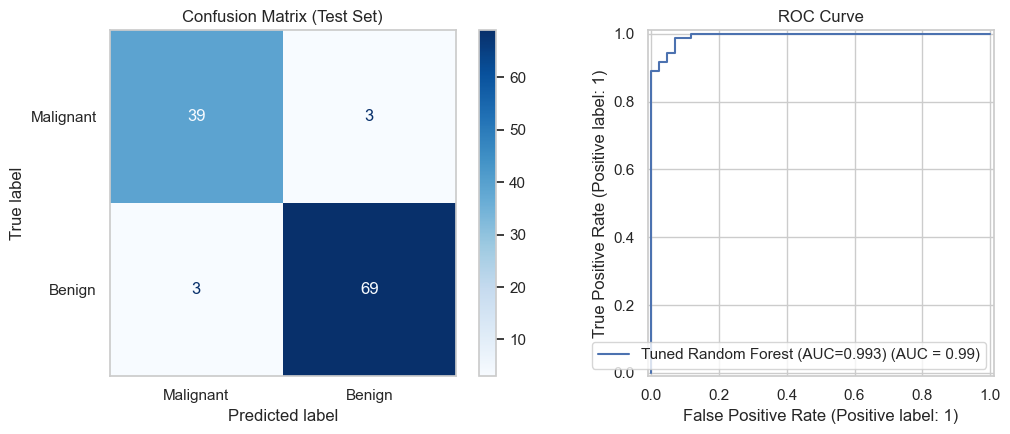

In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

# Predict on unseen test data
y_pred = best_model.predict(X_test_scaled)
y_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# Calculate Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("=== Final Test Set Evaluation Metrics ===")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print("\n" + "="*55)
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))

# Visual Evaluation: Confusion Matrix & ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Malignant', 'Benign'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix (Test Set)")
axes[0].grid(False)

# 2. ROC Curve
RocCurveDisplay.from_predictions(
    y_test, y_proba,
    name=f"Tuned Random Forest (AUC={auc:.3f})",
    ax=axes[1]
)
axes[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()

---
## Step 9: Final Output
- Performance summary comparing baseline, cross-validation, and final test score.
- Deployment test: Single-sample prediction function on new raw patient data.


In [10]:
# 1. Summary Comparison Table
summary_table = pd.DataFrame({
    'Stage': [
        '1. Baseline Training',
        '2. 5-Fold Cross-Validation (Train)',
        '3. Unseen Test Set Evaluation'
    ],
    'Accuracy (%)': [
        round(base_train_acc * 100, 2),
        round(cv_scores.mean() * 100, 2),
        round(acc * 100, 2)
    ],
    'Status': ['Fitted', 'Validated', 'Final Result']
})

print("=== Pipeline Performance Summary ===")
print(summary_table.to_string(index=False))

# 2. End-to-End Inference Demonstration on a New Patient Sample
def predict_patient(raw_sample_df, model, scaler, class_names):
    sample_scaled = scaler.transform(raw_sample_df)
    pred_idx = model.predict(sample_scaled)[0]
    probs = model.predict_proba(sample_scaled)[0]
    return class_names[pred_idx], probs[pred_idx] * 100, probs

# Test on patient 0 from test set
sample_patient = X_test.iloc[[0]]
actual_diagnosis = cancer_data.target_names[y_test.iloc[0]].capitalize()
pred_diagnosis, confidence, probs = predict_patient(sample_patient, best_model, scaler, cancer_data.target_names)

print("\n=== Single Patient Inference Output ===")
print(f"Actual Diagnosis:    {actual_diagnosis}")
print(f"Predicted Diagnosis: {pred_diagnosis.capitalize()}")
print(f"Confidence Level:    {confidence:.2f}%")
print(f"Class Probabilities: Malignant: {probs[0]:.4f}, Benign: {probs[1]:.4f}")

=== Pipeline Performance Summary ===
                             Stage  Accuracy (%)       Status
              1. Baseline Training        100.00       Fitted
2. 5-Fold Cross-Validation (Train)         94.95    Validated
     3. Unseen Test Set Evaluation         94.74 Final Result

=== Single Patient Inference Output ===
Actual Diagnosis:    Malignant
Predicted Diagnosis: Malignant
Confidence Level:    100.00%
Class Probabilities: Malignant: 1.0000, Benign: 0.0000
